# Klasifikasi Penyakit Daun Kacang Menggunakan EfficientNetB0 dan DenseNet121

**Kelompok D5 - Universitas Tarumanagara**  
535250161 Azzarqy Fizran M. Nasrun · 535250162 Bhariq Nafil R. Setiaddy · 535250163 Christofer Reinner

Notebook ini membangun eksperimen klasifikasi citra untuk tiga kelas daun kacang: `angular_leaf_spot`, `bean_rust`, dan `healthy`. Dua model yang dibandingkan adalah **EfficientNetB0** dan **DenseNet121**, keduanya menggunakan transfer learning dengan bobot ImageNet.

**Aturan eksperimen:** dataset resmi menyediakan split train, validation, dan test. Data test hanya digunakan sekali untuk evaluasi akhir. Jangan memindahkan gambar dari test ke train/validation. Notebook ini tidak memuat metrik rekaan; seluruh hasil akan dihitung saat sel dijalankan.

## 1. Persiapan runtime

Jalankan notebook ini di Google Colab. Disarankan menggunakan GPU T4 melalui **Runtime → Change runtime type → T4 GPU**. Jika TensorFlow yang tersedia berbeda, catat versinya pada laporan agar eksperimen dapat direproduksi.

In [ ]:
!pip -q install tensorflow-datasets==4.9.10 importlib_resources

In [ ]:
import os, json, time, random, zipfile, shutil, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Python: 3.13.16
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import importlib_resources

print("Python environment berhasil disiapkan!")
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)

print("GPU:", tf.config.list_physical_devices('GPU'))

Python environment berhasil disiapkan!
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip -q install datasets

## 2. Lokasi penyimpanan artefak

Artefak mencakup dua model `.keras`, nama kelas, tabel metrik, laporan klasifikasi, grafik, dan berkas ZIP. Google Drive digunakan supaya file model tetap tersedia setelah sesi Colab ditutup.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = Path('/content/drive/MyDrive/UAS_Bean_Leaf/artifacts')
except Exception:
    OUTPUT_DIR = Path('artifacts')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Folder artefak:', OUTPUT_DIR.resolve())

Mounted at /content/drive
Folder artefak: /content/drive/MyDrive/UAS_Bean_Leaf/artifacts


In [ ]:
from datasets import load_dataset

beans_dataset = load_dataset("AI-Lab-Makerere/beans")

print(beans_dataset)

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})


In [ ]:
print("Train:", len(beans_dataset["train"]))
print("Validation:", len(beans_dataset["validation"]))
print("Test:", len(beans_dataset["test"]))

print("\nFeatures:")
print(beans_dataset["train"].features)

print("\nContoh data:")
print(beans_dataset["train"][0])

Train: 1034
Validation: 133
Test: 128

Features:
{'image_file_path': Value('string'), 'image': Image(mode=None, decode=True), 'labels': ClassLabel(names=['angular_leaf_spot', 'bean_rust', 'healthy'])}

Contoh data:
{'image_file_path': '/home/albert/.cache/huggingface/datasets/downloads/extracted/967f0d9f61a7a8de58892c6fab6f02317c06faf3e19fba6a07b0885a9a7142c7/train/angular_leaf_spot/angular_leaf_spot_train.0.jpg', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x500 at 0x782FF54BFA10>, 'labels': 0}


In [ ]:

import numpy as np
import tensorflow as tf

# Ambil nama kelas dari dataset Hugging Face
CLASS_NAMES = beans_dataset["train"].features["labels"].names
NUM_CLASSES = len(CLASS_NAMES)

# Fungsi mengubah dataset Hugging Face menjadi TensorFlow Dataset
def convert_to_tf_dataset(hf_dataset):
    def generator():
        for sample in hf_dataset:
            image = sample["image"].convert("RGB")
            image = np.array(image, dtype=np.uint8)
            label = np.int64(sample["labels"])
            yield image, label

    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int64)
        )
    )

    return dataset

# Konversi masing-masing split
train_raw = convert_to_tf_dataset(beans_dataset["train"])
val_raw = convert_to_tf_dataset(beans_dataset["validation"])
test_raw = convert_to_tf_dataset(beans_dataset["test"])

print("Dataset berhasil dikonversi ke TensorFlow!")
print("Kelas:", CLASS_NAMES)
print("Jumlah kelas:", NUM_CLASSES)


Dataset berhasil dikonversi ke TensorFlow!
Kelas: ['angular_leaf_spot', 'bean_rust', 'healthy']
Jumlah kelas: 3


## 3. Memuat Beans Dataset

Beans berisi citra daun kacang yang diambil di lapangan. Dataset ini mempunyai tiga kelas penyakit/kondisi daun. Fungsi `tfds.load` mengambil split resmi tanpa menggabungkan data test ke data latih.

In [ ]:
import numpy as np
import tensorflow as tf

def count_labels(dataset, class_count):
    counts = np.zeros(class_count, dtype=np.int64)

    for _, label in tf.data.Dataset.as_numpy_iterator(dataset):
        counts[int(label)] += 1

    return counts

train_counts = count_labels(train_raw, NUM_CLASSES)
val_counts = count_labels(val_raw, NUM_CLASSES)
test_counts = count_labels(test_raw, NUM_CLASSES)

print("Distribusi Train:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {train_counts[i]}")

print("\nDistribusi Validation:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {val_counts[i]}")

print("\nDistribusi Test:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {test_counts[i]}")

Distribusi Train:
angular_leaf_spot: 345
bean_rust: 348
healthy: 341

Distribusi Validation:
angular_leaf_spot: 44
bean_rust: 45
healthy: 44

Distribusi Test:
angular_leaf_spot: 43
bean_rust: 43
healthy: 42


In [ ]:
def count_labels(dataset, class_count):
    counts = np.zeros(class_count, dtype=np.int64)
    for _, label in tfds.as_numpy(dataset):
        counts[int(label)] += 1
    return counts

split_counts = {
    'train': count_labels(train_raw, NUM_CLASSES),
    'validation': count_labels(val_raw, NUM_CLASSES),
    'test': count_labels(test_raw, NUM_CLASSES),
}

split_summary = pd.DataFrame(split_counts, index=CLASS_NAMES)
split_summary.loc['TOTAL'] = split_summary.sum(axis=0)
display(split_summary)
print('Total citra:', int(split_summary.loc['TOTAL'].sum()))

,train,validation,test
angular_leaf_spot,345,44,43
bean_rust,348,45,43
healthy,341,44,42
TOTAL,1034,133,128


Total citra: 1295


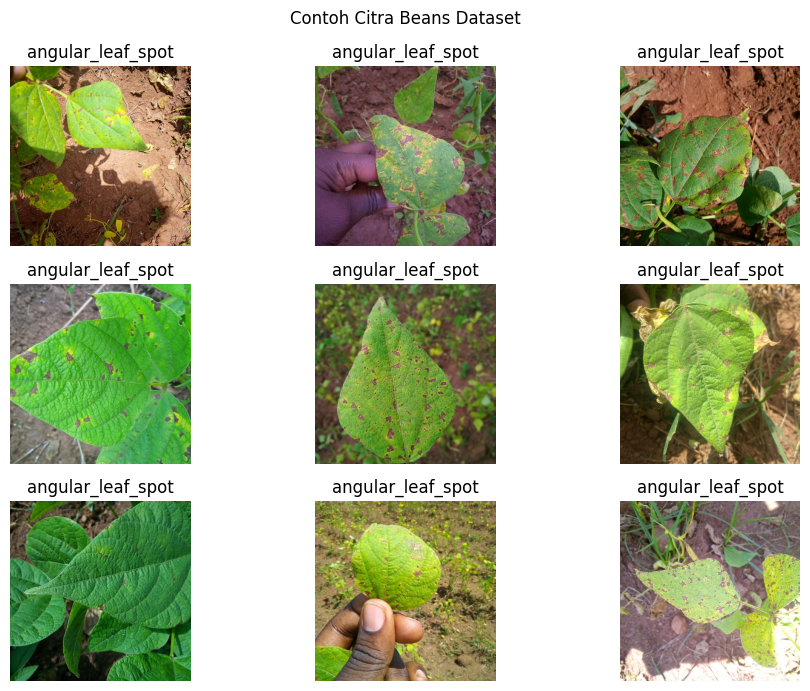

In [ ]:
# Contoh citra dari data training
plt.figure(figsize=(10, 7))
for idx, (image, label) in enumerate(train_raw.take(9)):
    ax = plt.subplot(3, 3, idx + 1)
    ax.imshow(image.numpy())
    ax.set_title(CLASS_NAMES[int(label.numpy())])
    ax.axis('off')
plt.suptitle('Contoh Citra Beans Dataset')
plt.tight_layout()
plt.show()

## 4. Preprocessing dan pipeline data

Semua citra diubah ke RGB dan di-resize ke 224×224 piksel. Nilai piksel dipertahankan pada rentang 0–255 karena preprocessing EfficientNetB0 sudah menjadi bagian dari model, sedangkan DenseNet121 menerima normalisasi tersendiri di dalam arsitektur. Augmentasi hanya diterapkan pada data training.

In [ ]:
def resize_image(image, label):
    image = tf.image.resize(image, IMG_SIZE, method='bilinear')
    image = tf.cast(image, tf.float32)
    return image, label


def make_train_dataset():
    return (
        train_raw
        .map(resize_image, num_parallel_calls=AUTOTUNE)
        .shuffle(1024, seed=SEED, reshuffle_each_iteration=True)
        .batch(BATCH_SIZE)
        .repeat()
        .prefetch(AUTOTUNE)
    )


train_ds = make_train_dataset()

val_ds = (
    val_raw
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

TRAIN_STEPS = 65
VAL_STEPS = 9
TEST_STEPS = 8

print("Train steps per epoch:", TRAIN_STEPS)
print("Validation steps:", VAL_STEPS)
print("Test steps:", TEST_STEPS)

for batch_images, batch_labels in train_ds.take(1):
    print("Shape batch:", batch_images.shape)
    print(
        "Rentang nilai:",
        float(tf.reduce_min(batch_images)),
        "sampai",
        float(tf.reduce_max(batch_images))
    )

Train steps per epoch: 65
Validation steps: 9
Test steps: 8
Shape batch: (16, 224, 224, 3)
Rentang nilai: 0.0 sampai 255.0


## 5. Membangun model transfer learning

Kedua model memakai input 224×224×3, bobot awal ImageNet, Global Average Pooling, Dropout, dan Dense Softmax tiga kelas. Pada EfficientNetB0, preprocessing skala disediakan oleh model Keras. Pada DenseNet121, input diskalakan ke rentang -1 hingga 1 sebelum backbone.

Tahap pelatihan pertama membekukan backbone. Tahap kedua membuka sebagian lapisan akhir untuk fine-tuning dengan learning rate lebih kecil. Batch Normalization tetap dibekukan agar pelatihan pada dataset yang relatif kecil lebih stabil.

In [ ]:
def build_transfer_model(model_name):
    inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name='image')

    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal'),
        tf.keras.layers.RandomRotation(0.06),
        tf.keras.layers.RandomZoom(0.08),
    ], name='training_augmentation')
    x = augmentation(inputs)

    if model_name == 'EfficientNetB0':
        backbone = tf.keras.applications.EfficientNetB0(
            include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3)
        )
        # EfficientNet Keras sudah memiliki preprocessing/rescaling internal.
    elif model_name == 'DenseNet121':
        backbone = tf.keras.applications.DenseNet121(
            include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3)
        )
        x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name='densenet_input_scale')(x)
    else:
        raise ValueError(f'Model tidak dikenal: {model_name}')

    backbone.trainable = False
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
    x = tf.keras.layers.Dropout(0.30, name='dropout')(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='classifier')(x)

    model = tf.keras.Model(inputs, outputs, name=model_name)
    return model, backbone


def merge_history(history_a, history_b):
    merged = {}
    keys = set(history_a.history) | set(history_b.history)
    for key in keys:
        merged[key] = history_a.history.get(key, []) + history_b.history.get(key, [])
    return pd.DataFrame(merged)

In [ ]:
def train_one_model(model_name, frozen_epochs=10, finetune_epochs=6):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    local_train_ds = make_train_dataset()

    model, backbone = build_transfer_model(model_name)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    callbacks_stage1 = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            min_lr=1e-6
        ),
    ]

    start_time = time.perf_counter()

    # Stage 1: Train classifier head
    history_frozen = model.fit(
        local_train_ds,
        validation_data=val_ds,
        epochs=frozen_epochs,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VAL_STEPS,
        callbacks=callbacks_stage1,
        verbose=1
    )

    # Stage 2: Fine-tuning 30 layer terakhir
    backbone.trainable = True

    for layer in backbone.layers[:-30]:
        layer.trainable = False

    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    callbacks_stage2 = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            min_lr=1e-7
        ),
    ]

    history_finetune = model.fit(
        local_train_ds,
        validation_data=val_ds,
        epochs=finetune_epochs,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VAL_STEPS,
        callbacks=callbacks_stage2,
        verbose=1
    )

    training_seconds = time.perf_counter() - start_time

    epoch_info = {
        'Head_Training_Epochs': len(history_frozen.epoch),
        'Fine_Tuning_Epochs': len(history_finetune.epoch),
    }

    history_df = merge_history(
        history_frozen,
        history_finetune
    )

    model_path = OUTPUT_DIR / f'{model_name.lower()}.keras'

    model.save(model_path)

    history_df.to_csv(
        OUTPUT_DIR / f'{model_name.lower()}_history.csv',
        index=False
    )

    print(f'{model_name} tersimpan ke {model_path}')
    print('Epoch head / fine-tuning:', epoch_info)
    print(f'Waktu training: {training_seconds:.2f} detik')

    return model, history_df, training_seconds, epoch_info

## 6. Melatih kedua arsitektur

Model dilatih dengan konfigurasi yang sama sejauh mungkin. Karena kondisi komputasi dan perilaku early stopping dapat memengaruhi durasi, waktu aktual dicatat dari eksekusi notebook, bukan ditulis manual.

In [ ]:
trained_models = {}
training_histories = {}
training_times = {}
training_epochs = {}

for architecture in ['EfficientNetB0', 'DenseNet121']:
    print('\n' + '=' * 70)
    print('TRAINING:', architecture)
    print('=' * 70)
    model, history_df, seconds, epoch_info = train_one_model(architecture)
    trained_models[architecture] = model
    training_histories[architecture] = history_df
    training_times[architecture] = seconds
    training_epochs[architecture] = epoch_info


TRAINING: EfficientNetB0
Epoch 1/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 25s 156ms/step - accuracy: 0.6538 - loss: 0.7827 - val_accuracy: 0.7519 - val_loss: 0.6244 - learning_rate: 0.0010
Epoch 2/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.7814 - loss: 0.5571 - val_accuracy: 0.8045 - val_loss: 0.5209 - learning_rate: 0.0010
Epoch 3/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.8317 - loss: 0.4706 - val_accuracy: 0.7820 - val_loss: 0.5008 - learning_rate: 0.0010
Epoch 4/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.8385 - loss: 0.4418 - val_accuracy: 0.8271 - val_loss: 0.4213 - learning_rate: 0.0010
Epoch 5/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.8627 - loss: 0.3904 - val_accuracy: 0.8195 - val_loss: 0.4111 - learning_rate: 0.0010
Epoch 6/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - accuracy: 0.8849 - loss: 0.3569 - val_accuracy: 0.8346 - val_loss: 0.3897 - learning_rate: 0.0010
Epoch 7/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.

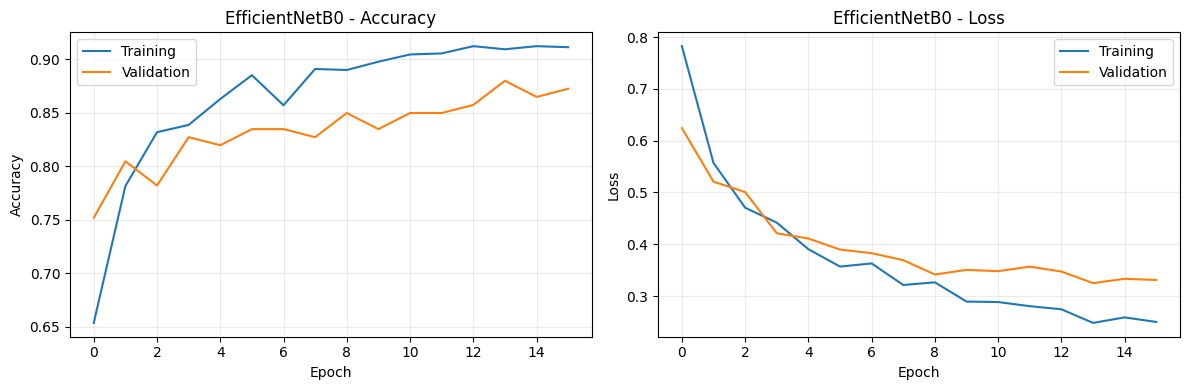

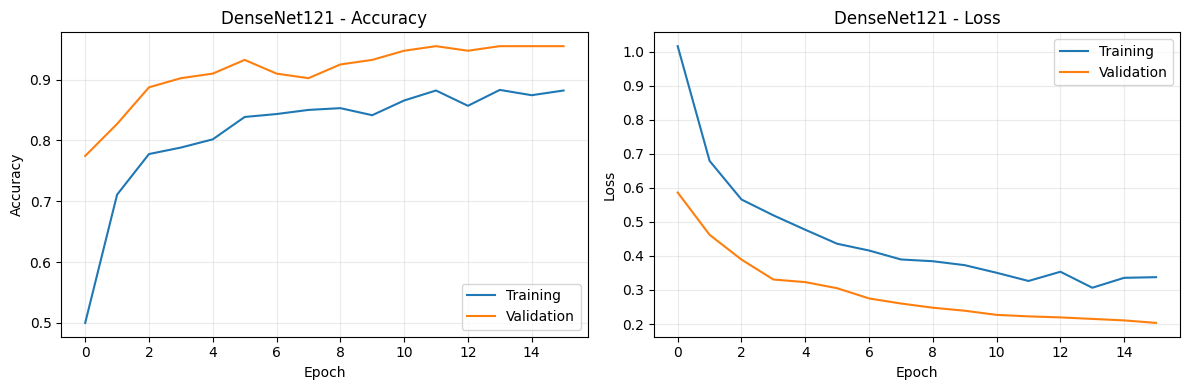

In [ ]:
# Visualisasi kurva akurasi dan loss untuk masing-masing model
for architecture, history_df in training_histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if 'accuracy' in history_df:
        axes[0].plot(history_df['accuracy'], label='Training')
    if 'val_accuracy' in history_df:
        axes[0].plot(history_df['val_accuracy'], label='Validation')
    axes[0].set_title(f'{architecture} - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    if 'loss' in history_df:
        axes[1].plot(history_df['loss'], label='Training')
    if 'val_loss' in history_df:
        axes[1].plot(history_df['val_loss'], label='Validation')
    axes[1].set_title(f'{architecture} - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{architecture.lower()}_training_curves.png', dpi=160, bbox_inches='tight')
    plt.show()

## 7. Evaluasi pada test split

Metrik utama adalah accuracy, macro-precision, macro-recall, macro-F1, dan waktu pelatihan. Macro-average memberi bobot sama pada setiap kelas. Confusion matrix digunakan untuk melihat kelas mana yang paling sering tertukar.

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


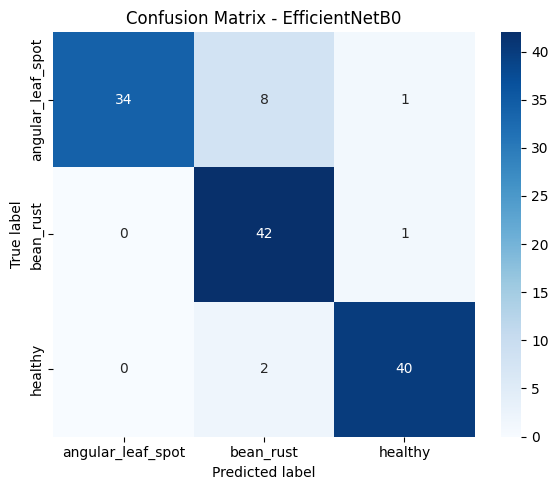

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


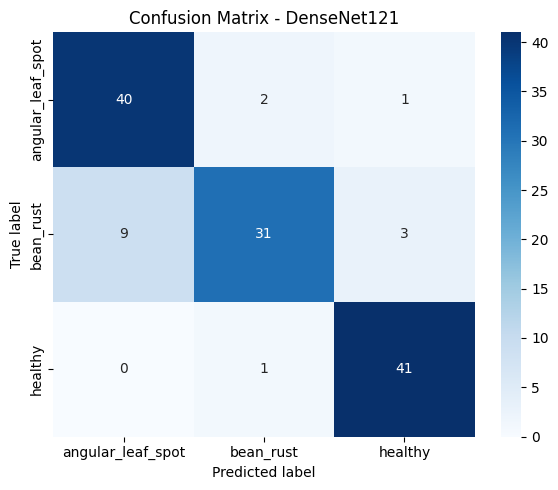

,Model,Precision_Macro,Recall_Macro,Accuracy,F1_Macro,Training_Time_Seconds,Parameters,Head_Training_Epochs,Fine_Tuning_Epochs
0,EfficientNetB0,0.9200,0.9066,0.9062,0.9066,171.6060,4053414,10,6
1,DenseNet121,0.8797,0.8758,0.8750,0.8724,222.6289,7040579,10,6


In [ ]:
def evaluate_model(model_name, model, train_seconds):
    y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
    probabilities = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    epoch_info = training_epochs[model_name]
    metrics = {
        'Model': model_name,
        'Precision_Macro': float(precision_score(y_true, y_pred, average='macro', zero_division=0)),
        'Recall_Macro': float(recall_score(y_true, y_pred, average='macro', zero_division=0)),
        'Accuracy': float(accuracy_score(y_true, y_pred)),
        'F1_Macro': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'Training_Time_Seconds': float(train_seconds),
        'Parameters': int(model.count_params()),
        'Head_Training_Epochs': int(epoch_info['Head_Training_Epochs']),
        'Fine_Tuning_Epochs': int(epoch_info['Fine_Tuning_Epochs']),
    }

    report = classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / f'{model_name.lower()}_classification_report.csv')

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{model_name.lower()}_confusion_matrix.png', dpi=160, bbox_inches='tight')
    plt.show()

    pred_df = pd.DataFrame({
        'true_label': [CLASS_NAMES[i] for i in y_true],
        'predicted_label': [CLASS_NAMES[i] for i in y_pred],
        'confidence': np.max(probabilities, axis=1),
    })
    pred_df.to_csv(OUTPUT_DIR / f'{model_name.lower()}_test_predictions.csv', index=False)
    return metrics

results = []
for architecture, model in trained_models.items():
    results.append(evaluate_model(architecture, model, training_times[architecture]))

results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
display(results_df.round(4))

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

for architecture, model in trained_models.items():

    print("=" * 60)
    print(f"CLASSIFICATION REPORT: {architecture}")
    print("=" * 60)

    y_true = np.concatenate([
        labels.numpy() for _, labels in test_ds
    ])

    predictions = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    print(f"Test Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)\n")

    print(classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    ))

CLASSIFICATION REPORT: EfficientNetB0


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Test Accuracy: 0.9062 (90.62%)

                   precision    recall  f1-score   support

angular_leaf_spot     1.0000    0.7907    0.8831        43
        bean_rust     0.8077    0.9767    0.8842        43
          healthy     0.9524    0.9524    0.9524        42

         accuracy                         0.9062       128
        macro avg     0.9200    0.9066    0.9066       128
     weighted avg     0.9198    0.9062    0.9062       128

CLASSIFICATION REPORT: DenseNet121
Test Accuracy: 0.8750 (87.50%)

                   precision    recall  f1-score   support

angular_leaf_spot     0.8163    0.9302    0.8696        43
        bean_rust     0.9118    0.7209    0.8052        43
          healthy     0.9111    0.9762    0.9425        42

         accuracy                         0.8750       128
        macro avg     0.8797    0.8758    0.8724       128
     weighted avg     0.8795    0.8750    0.8719       128



/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


## 8. Menyimpan konfigurasi dan membuat paket model untuk aplikasi

File model disimpan dalam format Keras `.keras`. Aplikasi Streamlit akan memuat model tersebut untuk memprediksi gambar baru. File gambar pengguna tidak disimpan dalam database aplikasi; yang disimpan adalah metadata prediksi dan hash gambar.

In [ ]:
with open(OUTPUT_DIR / 'class_names.json', 'w', encoding='utf-8') as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=2)

with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

manifest = {
    'project': 'Bean Leaf Disease Classification',
    'input_size': list(IMG_SIZE),
    'classes': CLASS_NAMES,
    'model_files': {
        'EfficientNetB0': 'efficientnetb0.keras',
        'DenseNet121': 'densenet121.keras'
    },
    'tensorflow_version': tf.__version__,
    'seed': SEED,
    'training_epochs': training_epochs,
    'training_time_seconds': training_times,
    'note': 'Raw RGB input in 0..255 range. Preprocessing is included in each saved model.'
}
with open(OUTPUT_DIR / 'model_manifest.json', 'w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

bundle_path = OUTPUT_DIR / 'bean_leaf_models_bundle.zip'
with zipfile.ZipFile(bundle_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in [
        'efficientnetb0.keras', 'densenet121.keras', 'class_names.json',
        'metrics.json', 'model_manifest.json', 'model_comparison.csv'
    ]:
        file_path = OUTPUT_DIR / filename
        if file_path.exists():
            zf.write(file_path, arcname=filename)

print('Artefak selesai dibuat:')
for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        print(f'- {file_path.name}: {file_path.stat().st_size / (1024*1024):.2f} MB')

Artefak selesai dibuat:
- bean_leaf_models_bundle.zip: 53.53 MB
- class_names.json: 0.00 MB
- densenet121.keras: 33.16 MB
- densenet121_classification_report.csv: 0.00 MB
- densenet121_confusion_matrix.png: 0.04 MB
- densenet121_history.csv: 0.00 MB
- densenet121_test_predictions.csv: 0.00 MB
- densenet121_training_curves.png: 0.08 MB
- efficientnetb0.keras: 27.64 MB
- efficientnetb0_classification_report.csv: 0.00 MB
- efficientnetb0_confusion_matrix.png: 0.04 MB
- efficientnetb0_history.csv: 0.00 MB
- efficientnetb0_test_predictions.csv: 0.00 MB
- efficientnetb0_training_curves.png: 0.08 MB
- metrics.json: 0.00 MB
- model_comparison.csv: 0.00 MB
- model_manifest.json: 0.00 MB


## 9. Unduh paket model

Setelah seluruh sel selesai tanpa error, unduh ZIP berikut dari Google Colab. Ekstrak isi ZIP ke folder `app/models/` di project aplikasi. Jangan mengubah nama file model.

In [ ]:
try:
    from google.colab import files
    files.download(str(OUTPUT_DIR / 'bean_leaf_models_bundle.zip'))
except Exception:
    print('Paket tersimpan di:', (OUTPUT_DIR / 'bean_leaf_models_bundle.zip').resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>